In [1]:
import sys
sys.path.append("/home/macbuse/miniconda3/lib/python3.11/site-packages")

import numpy as np
import itertools

import matplotlib as mpl

mpl.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "text.latex.preamble": r"\usepackage{amsmath}",
})

import matplotlib.pyplot as plt
import matplotlib.patches as patches


def x2c(x):
    c,r = .5*(x - 1/x),.5*abs(x + 1/x)
    return c,r


def add_circle(
    ax, 
    center_x, center_y, radius, 
    fill=True, linewidth=1,
    **kwargs
):
    """Helper to add a Euclidean circle 
    patch to the upper half-plane.
    """
    circle = patches.Circle(
        (center_x, center_y), 
        radius, 
        fill=fill, 
        **kwargs
    )
    ax.add_patch(circle)

In [6]:
P % 7

array([1, 2, 5, 5, 1, 0, 1, 2, 5, 5, 1, 0, 1, 2, 5, 5, 1])

fib is period 8 mod 7
pell is period 3 mod 7

In [7]:
L = [1,1]
for _ in range(20):
    L.append(L[-1] + L[-2])
L = np.array(L)
L[::2] 

array([    1,     2,     5,    13,    34,    89,   233,   610,  1597,
        4181, 10946])

$ (2cx)^2 + c^2  = (a+d)^2 - 4$

---

# recurrences, recurrences

$$\tan^2 \theta = \frac{y^2}{(3/2)^2 - y^2} = \frac{1}{(3/2y)^2 - 1} = \frac{1}{\sinh^2 (\frac12 \ell_\gamma)}$$

For $2 \cosh (\frac12 \ell_\gamma) = 3$

In [185]:
np.linalg.det(V[:9].reshape(3,3))

np.float64(-7077887.999999307)

In [188]:
len(V)

10

n   | Center     | Apex Height (r)
-----------------------------------
0   | -0.5000    | 1.1180         
1   | -1.0000    | 1.4142         
2   | -1.1000    | 1.4866         
3   | -1.1154    | 1.4980         
4   | -1.1176    | 1.4997         
5   | -1.1180    | 1.5000         


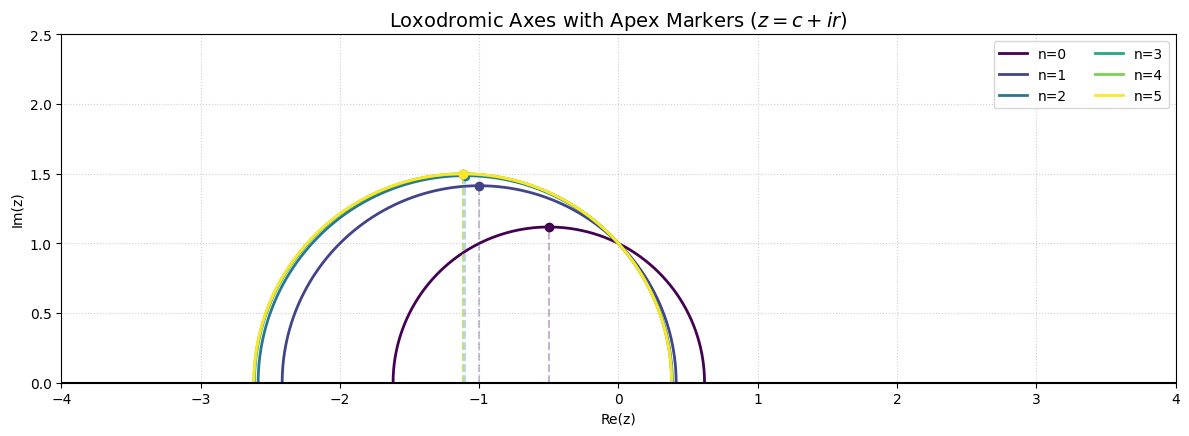

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def m2a(A):
    """Calculates center and radius of the axis of a loxodromic transformation."""
    a, b, c, d = A.astype(float).ravel()
    # Discriminant delta = trace^2 - 4
    delta = (a + d)**2 - 4
    radius = np.sqrt(delta) / (2 * c)
    center = (a - d) / (2 * c)
    return center, radius

# Matrices
A = np.array([[1, 1], [1, 2]], dtype=int)
B = np.array([[2, 1], [1, 1]], dtype=int)
Q = np.array([[1, 1], [0, 1]], dtype=int)
q = np.array([[1, -1], [0, 1]], dtype=int)

AA = q @ A @ Q
C_iter = q @ B @ Q

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_aspect("equal")

T = np.linspace(0, np.pi, 500)
Z = np.exp(1J * T)
colors = plt.cm.viridis(np.linspace(0, 1, 6))

print(f"{'n':<3} | {'Center':<10} | {'Apex Height (r)':<15}")
print("-" * 35)

for i in range(6):
    c, r = m2a(C_iter)
    W = r * Z + c
    
    # Plot Arc
    ax.plot(W.real, W.imag, color=colors[i], lw=2, label=f'n={i}')
    
    # Mark Apex
    ax.plot(c, r, 'o', color=colors[i], markersize=6)
    ax.vlines(c, 0, r, color=colors[i], linestyle='--', alpha=0.3)
    
    # Print values for verification
    print(f"{i:<3} | {c:<10.4f} | {r:<15.4f}")
    
    C_iter = C_iter @ AA

# Formatting
ax.axhline(0, color='black', lw=1.5) # The Real Axis
ax.set_xlim(-4, 4)
ax.set_ylim(0, 2.5)
ax.set_title("Loxodromic Axes with Apex Markers ($z = c + ir$)", fontsize=14)
ax.set_xlabel("Re(z)")
ax.set_ylabel("Im(z)")
ax.legend(loc='upper right', ncol=2)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

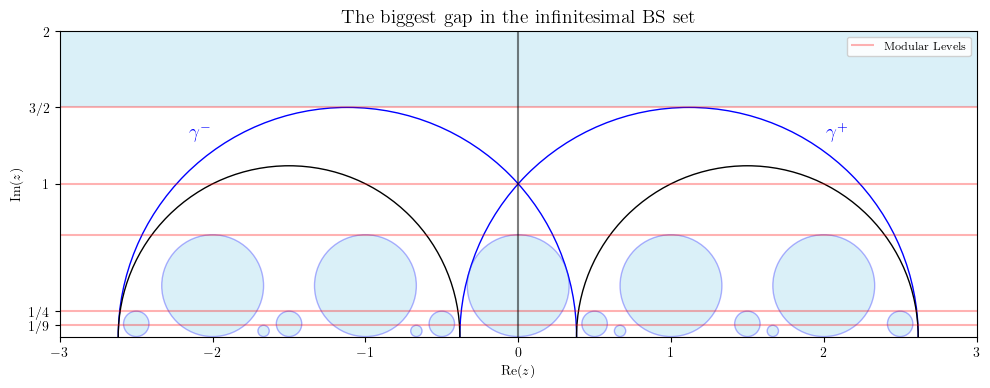

In [21]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# Plotting Setup
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_aspect("equal")

def add_circle(
    ax, 
    center_x, center_y, radius, 
    fill=True, linewidth=1,
    **kwargs
):
    """Helper to add a Euclidean circle 
    patch to the upper half-plane.
    """
    circle = patches.Circle(
        (center_x, center_y), 
        radius, 
        fill=fill, 
        **kwargs
    )
    ax.add_patch(circle)

# 1. Geodesics tangent to horocycle at \infty
for c, r in [(np.sqrt(5)/2, 3/2), (-np.sqrt(5)/2, 3/2)]:
    add_circle(
        ax, c, 0, r, 
        fill=False, color='blue', 
        linewidth=1
    )

for c, r in [(3/2,np.sqrt(5)/2), (-3/2,np.sqrt(5)/2)]:
    add_circle(
        ax, c, 0, r, 
        fill=False, color='k', 
        linewidth=1
    )



# 2. Horoballs (filled with transparency)
# Scale 1/3
for x in range(-2, 3):
    add_circle(
        ax, x, 1/3, 1/3, 
        facecolor='skyblue', edgecolor='blue', 
        alpha=0.3, 
    )

# Scale 1/12
for x in np.arange(0, 6) - 2.5:
    add_circle(
        ax, x, 1/12, 1/12, 
        facecolor='skyblue',  alpha=0.3, 
        edgecolor='blue', 
    )

# Scale 5^2 + 3^2 = 34 (symmetric pairs)
for x in [2/3, 5/3]:
    add_circle(
        ax, x, 1/27, 1/27, 
        facecolor='skyblue', edgecolor='blue',
        alpha=0.3,  
    )
    add_circle(
        ax, -x, 1/27, 1/27, 
        facecolor='skyblue', edgecolor='blue',
        alpha=0.3,  
    )



# 3. Reference lines
ax.hlines(
    [1, 2/3, 1.5, 2/3/2**2, 2/3/3**2], 
    -5, 5, 
    colors='r',  alpha=0.3, 
    label='Modular Levels'
)

# Top filled rectangle from y = 3/2 to 2
rect = patches.Rectangle(
    (-3, 1.5), 
    6, 0.5, 
    facecolor='skyblue',  alpha=0.3, edgecolor='none'
)

ax.add_patch(rect)
ax.vlines(0,  0, 2,  
    colors='k', alpha=0.5
)

# Labels for the two blue geodesics
c = np.sqrt(5) / 2
r = 3 / 2
offset = 0.06  # radial padding outside the arc

theta_pos = np.deg2rad(55)
ax.text(
    c + (r + offset) * np.cos(theta_pos),
    (r + offset) * np.sin(theta_pos),
    r"$\gamma^+$",
    color="blue",
    fontsize=14,
    ha="left",
    va="bottom",
)

theta_neg = np.deg2rad(125)
ax.text(
    -c + (r + offset) * np.cos(theta_neg),
    (r + offset) * np.sin(theta_neg),
    r"$\gamma^-$",
    color="blue",
    fontsize=14,
    ha="right",
    va="bottom",
)

# View configuration
ax.set_xlim(-3, 3)
ax.set_ylim(0, 2)

ax.set_title(
    "The biggest gap in the infinitesimal BS set", 
    fontsize=14
)
ax.set_xlabel(r"$\text{Re}(z)$")
ax.set_ylabel(r"$\text{Im}(z)$")
ax.legend(
    loc='upper right', 
    fontsize='small', 
    framealpha=0.9
)

# Custom ticks on the y-axis
ax.set_yticks([0.25*2/3, 1, 3/2, 2, 1/9*2/3])
ax.set_yticklabels(['1/4', '1', '3/2', '2', '1/9'])

plt.tight_layout()

plt.savefig('big_gap.png')

In [71]:
PP  = np.arctan(np.array([2/np.sqrt(5), 
                        1/np.sqrt(8), 
                        1/np.sqrt(24),
                        1/np.sqrt(168)])) /np.pi

In [73]:
2*sum(PP[:-1]) - sum(PP[:2])

np.float64(0.46864140886611255)

-1.7043226167256327
-1.6302216333897357


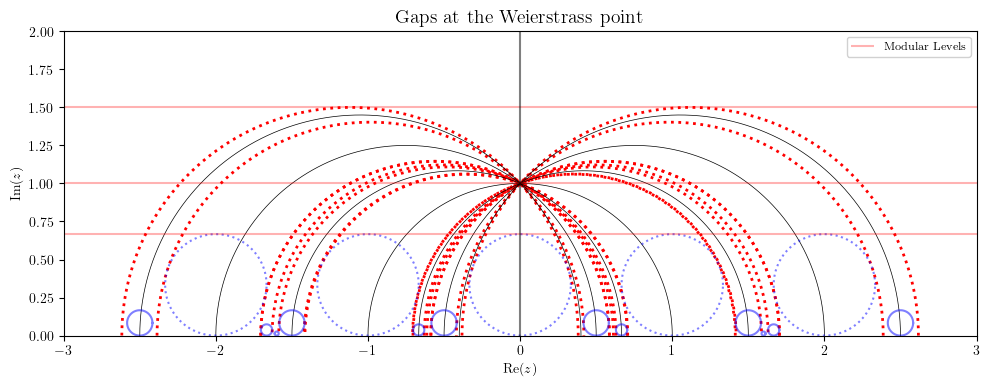

In [14]:
# Plotting Setup
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_aspect("equal")

# Arc resolution
T = np.linspace(0, np.pi, 200)
Z = np.exp(1J * T)
H = np.exp(2J * T)


# Sequence colors
colors = plt.cm.viridis(np.linspace(0, 1, 6))

for C in [(np.sqrt(5)/2, 3/2), (-np.sqrt(5)/2, 3/2) ]:
    c,r =  C
    W = r * Z + c   
    # Plot Arc
    ax.plot(W.real, W.imag, "r:", lw=2)

# lines tangent to horoballs
y = 2
cc = np.sqrt( (3/2)**2 - 1/y**2)
x = y*(3/2 + cc)
x = (x+1)/(x-1)
for x in [x,1/x]:
    c,r =  x2c(x)
    W = r * Z + c   
    # Plot Arc
    ax.plot(W.real, W.imag, 'r:', lw=2)


y = 5
cc = np.sqrt( (3/2)**2 - 1/y**2)
ep = y*(3/2 + cc)
for x in [ep,-ep]:
    x = (2*x+1)/(x-2)

    c,r =  x2c(x)   
    W = r * Z + c   
    ax.plot(W.real, W.imag, 'r:', lw=2) 
    ax.plot(-W.real, W.imag, 'r:', lw=2)


y = 13
cc = np.sqrt( (3/2)**2 - 1/y**2)
ep = y*(3/2 + cc)
for x in [ep,-ep]:
    x = (3*x+2)/(-2*x+3)

    c,r =  x2c(x)   
    W = r * Z + c   
    ax.plot(W.real, W.imag, 'r:', lw=2) 
    ax.plot(-W.real, W.imag, 'r:', lw=2)

y = 34
cc = np.sqrt( (3/2)**2 - 1/y**2)
ep = y*(3/2 + cc)
for x in [ep,-ep]:
    x = (5*x+3)/(-3*x+5)
    print(x)
    c,r =  x2c(x)   
    W = r * Z + c   
    ax.plot(W.real, W.imag, 'r:', lw=2) 
    ax.plot(-W.real, W.imag, 'r:', lw=2)

# arcs ending at cusps
for x in [5/2, 2, 3/2,  1, 1/2]:
    c,r =  x2c(x)
    W = r * Z + c   
    # Plot Arc
    ax.plot(W.real, W.imag, 'k', lw=.5)
    if x not in [2,1,1/2]:
        ax.plot(-W.real, W.imag, 'k', lw=.5)
        
# horoballs

for x in range(-2,3):
    W =  1/3*(H) + 1/3*1J + x 
    # Plot Arc
    ax.plot(W.real, W.imag, 'b:', alpha=0.5)

for x in np.arange(0,6) - 2.5:
    W =  1/3/4*(H) + 1/3/4*1J + x 
    # Plot Arc
    ax.plot(W.real, W.imag, 'b', alpha=0.5)

for x in [2/3, 5/3]:
    # 13,34
    W =  1/3/9*(H) + 1/3/9*1J + x
    # Plot Arc
    ax.plot(W.real, W.imag, 'b', alpha=0.5)
    ax.plot(- W.real, W.imag, 'b', alpha=0.5)

W =  1/3/25*(H) + 1/3/25*1J + 8/5
# Plot Arc
ax.plot(W.real, W.imag, 'b', alpha=0.5)
ax.plot(- W.real, W.imag, 'b', alpha=0.5)


# horizontal lines etc
plt.hlines([1, 2/3,1.5], -5, 5, colors='r', 
           alpha=0.3, label='Modular Levels')
plt.vlines(0, 0, 2, colors='k',
           alpha=0.5)

# Centering the view on 0
ax.set_xlim(-3, 3)
ax.set_ylim(0, 2)

ax.set_title("Gaps at the Weierstrass point", fontsize=14)
ax.set_xlabel("$\\text{Re}(z)$")
ax.set_ylabel("$\\text{Im}(z)$")
ax.legend(loc='upper right', fontsize='small', framealpha=0.9)

plt.tight_layout()
plt.show()

In [70]:
PP[0]

np.float64(0.23227952719876999)

In [67]:
1/np.sqrt(5)

np.float64(0.4472135954999579)

In [119]:
np.arange(0,6) - 2.5

array([-2.5, -1.5, -0.5,  0.5,  1.5,  2.5])

7.0
-3.4955317926133973


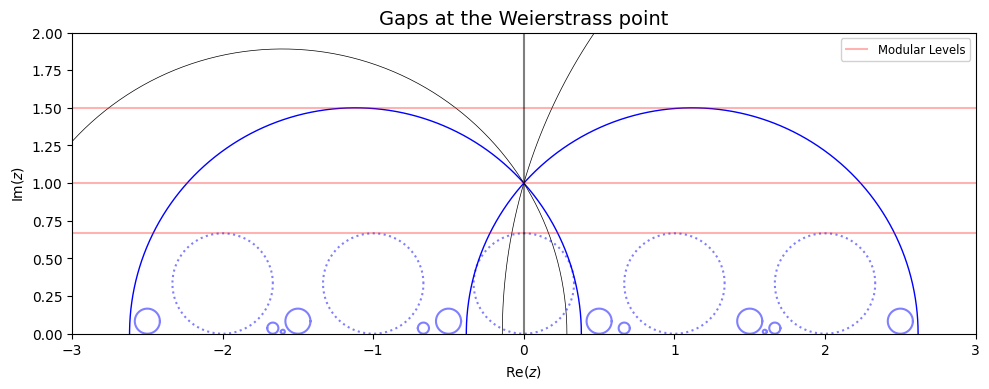

In [78]:
# Plotting Setup
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_aspect("equal")

# Arc resolution
T = np.linspace(0, np.pi, 200)
Z = np.exp(1J * T)
H = np.exp(2J * T)


# Sequence colors
colors = plt.cm.viridis(np.linspace(0, 1, 6))

for C in [(np.sqrt(5)/2, 3/2), (-np.sqrt(5)/2, 3/2) ]:
    c,r =  C
    W = r * Z + c   
    # Plot Arc
    ax.plot(W.real, W.imag, "b", lw=1)


# rotate 
for x in [1, np.sqrt(5)/2  + 3/2]:
    x = (4*x+3)/(-3*x+4)
    c,r =  x2c(x)   
    W = r * Z + c   
    ax.plot(W.real, W.imag, 'k', lw=.5) 

        
# horoballs

for x in range(-2,3):
    W =  1/3*(H) + 1/3*1J + x 
    # Plot Arc
    ax.plot(W.real, W.imag, 'b:', alpha=0.5)

for x in np.arange(0,6) - 2.5:
    W =  1/3/4*(H) + 1/3/4*1J + x 
    # Plot Arc
    ax.plot(W.real, W.imag, 'b', alpha=0.5)

for x in [2/3, 5/3]:
    # 13,34
    W =  1/3/9*(H) + 1/3/9*1J + x
    # Plot Arc
    ax.plot(W.real, W.imag, 'b', alpha=0.5)
    ax.plot(- W.real, W.imag, 'b', alpha=0.5)

W =  1/3/25*(H) + 1/3/25*1J + 8/5
# Plot Arc
ax.plot(W.real, W.imag, 'b', alpha=0.5)
ax.plot(- W.real, W.imag, 'b', alpha=0.5)


# horizontal lines etc
plt.hlines([1, 2/3,1.5], -5, 5, colors='r', 
           alpha=0.3, label='Modular Levels')
plt.vlines(0, 0, 2, colors='k',
           alpha=0.5)

# Centering the view on 0
ax.set_xlim(-3, 3)
ax.set_ylim(0, 2)

ax.set_title("Gaps at the Weierstrass point", fontsize=14)
ax.set_xlabel("$\\text{Re}(z)$")
ax.set_ylabel("$\\text{Im}(z)$")
ax.legend(loc='upper right', fontsize='small', framealpha=0.9)

plt.tight_layout()
plt.show()


In [153]:
np.sqrt(5)/2  + 3/2

np.float64(2.618033988749895)

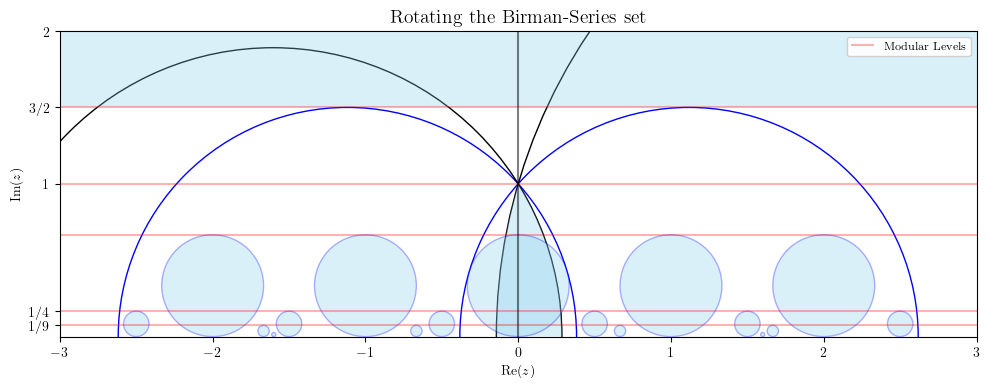

In [7]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# Plotting Setup
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_aspect("equal")

def add_circle(
    ax, 
    center_x, 
    center_y, 
    radius, 
    fill=True, 
    linewidth=1,
    **kwargs
):
    """Helper to add a Euclidean circle 
    patch to the upper half-plane.
    """
    circle = patches.Circle(
        (center_x, center_y), 
        radius, 
        fill=fill, 
        **kwargs
    )
    ax.add_patch(circle)

# 1. Geodesics tangent to horocycle at \infty
for c, r in [
    (np.sqrt(5)/2, 3/2), 
    (-np.sqrt(5)/2, 3/2)
]:
    add_circle(
        ax, c, 0, r, 
        fill=False, color='blue', 
        linewidth=1
    )

# Store the circle parameters as you loop
region_bounds = []

for x_val in [1, np.sqrt(5)/2 + 3/2]:
    x_mapped = (4 * x_val + 3) / (-3 * x_val + 4)
    c, r = x2c(x_mapped)
    region_bounds.append((c, r))
    add_circle(
        ax, c, 0, r, 
        fill=False, 
        edgecolor='black', 
        linewidth=0.5
    )

# Fill the region bounded by the two semicircles and the x-axis
# (Assuming the region lies between the innermost roots of the two semicircles)
c1, r1 = region_bounds[0]
c2, r2 = region_bounds[1]

# Determine the x range for the region between them
x_min = max(c1 - r1, c2 - r2)
x_max = min(c1 + r1, c2 + r2)

x_fill = np.linspace(x_min, x_max, 1000)
y1 = np.sqrt(np.maximum(0, r1**2 - (x_fill - c1)**2))
y2 = np.sqrt(np.maximum(0, r2**2 - (x_fill - c2)**2))

# Fill between the lower envelope of the two semicircles and the x-axis 
# (or whichever boundary matches your specific domain layout)
ax.fill_between(
    x_fill, 
    0, 
    np.minimum(y1, y2), 
    facecolor='skyblue', 
    alpha=0.3
)


# 2. Horoballs (filled with transparency)
# Scale 1/3
for x in range(-2, 3):
    add_circle(
        ax, x, 1/3, 1/3, 
        facecolor='skyblue', edgecolor='blue', 
        alpha=0.3, 
    )

# Scale 1/12
for x in np.arange(0, 6) - 2.5:
    add_circle(
        ax, x, 1/12, 1/12, 
        facecolor='skyblue',  alpha=0.3, 
        edgecolor='blue', 
    )

# Scale 5^2 + 3^2 = 34 (symmetric pairs)
for x in [2/3, 5/3]:
    add_circle(
        ax, x, 1/27, 1/27, 
        facecolor='skyblue', edgecolor='blue',
        alpha=0.3,  
    )
    add_circle(
        ax, -x, 1/27, 1/27, 
        facecolor='skyblue', edgecolor='blue',
        alpha=0.3,  
    )

# 8^2 + 5^2 = 89 (symmetric pair)
for x in [8/5, -8/5]:
    add_circle(
        ax, x, 1/3/5**2, 1/3/5**2, 
        facecolor='skyblue', edgecolor='blue',
        alpha=0.3, 
    )

# 3. Reference lines
ax.hlines(
    [1, 2/3, 1.5, 2/3/2**2, 2/3/3**2], 
    -5, 5, 
    colors='r',  alpha=0.3, 
    label='Modular Levels'
)

# Top filled rectangle from y = 3/2 to 2
rect = patches.Rectangle(
    (-3, 1.5), 
    6, 0.5, 
    facecolor='skyblue',  alpha=0.3, edgecolor='none'
)

ax.add_patch(rect)
ax.vlines(0,  0, 2,  
    colors='k', alpha=0.5
)

# View configuration
ax.set_xlim(-3, 3)
ax.set_ylim(0, 2)

ax.set_title(
    "Rotating the Birman-Series set", 
    fontsize=14
)
ax.set_xlabel(r"$\text{Re}(z)$")
ax.set_ylabel(r"$\text{Im}(z)$")
ax.legend(
    loc='upper right', 
    fontsize='small', 
    framealpha=0.9
)

# Custom ticks on the y-axis
ax.set_yticks([0.25*2/3, 1, 3/2, 2, 1/9*2/3])
ax.set_yticklabels(['1/4', '1', '3/2', '2', '1/9'])

plt.tight_layout()

plt.savefig('5_rotated.png')


In [10]:
pwd


'/home/macbuse/BS_ROTATE'

In [27]:
(1-1J)*(1+4J)

(5+3j)

$$d(0, t) = \ln\left(\frac{1 + \vert{}t\vert{}}{1 - \vert{}t\vert{}}\right) = 2\,\operatorname{artanh}(\vert{}t\vert{})$$

findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern Roman
findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern Roman
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern Roman
findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern Roman
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern Roman
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern Roman


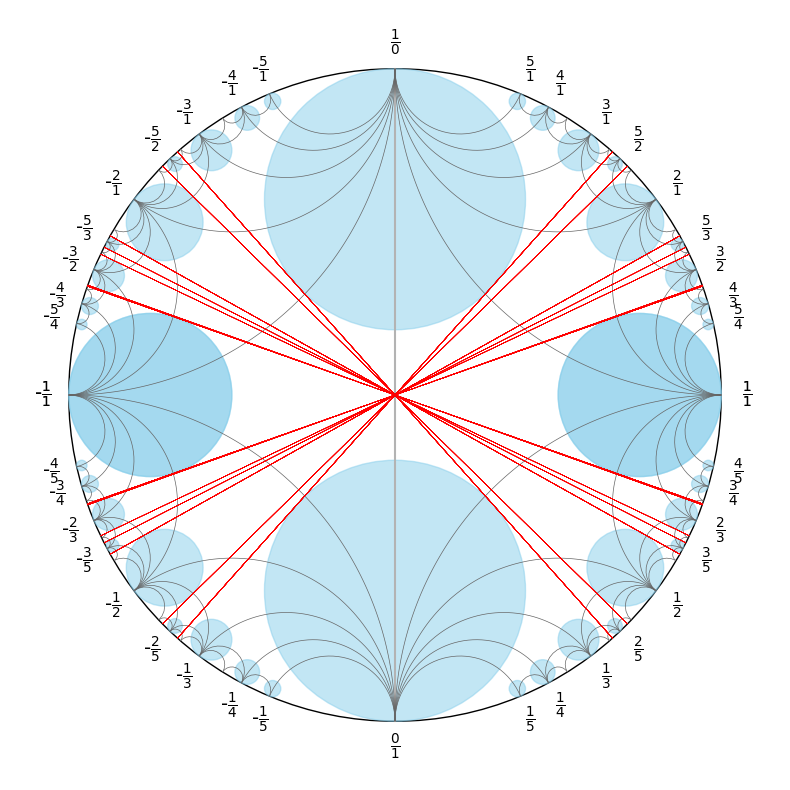

In [2]:
def farey(n: int) -> np.ndarray:
    """Return Farey-type mediant subdivisions of [-1/1, 0/1, 1/1] at depth n."""
    F = np.array([[-1, 1], [0, 1], [1, 1]], dtype=int)
    for _ in range(n):
        nxt = np.empty((2 * len(F) - 1, 2), dtype=int)
        nxt[::2] = F
        nxt[1::2] = F[:-1] + F[1:]
        F = nxt
    return F
    
def cayley(z: complex | np.ndarray) -> complex | np.ndarray:
    """Map the upper half-plane to the unit disk (-1 -> -1, 1 -> 1, 0 -> -i)."""
    return 1j * (z - 1j) / (z + 1j)

def seg2arc(a,b):
    '''a,b points on the unit circle
    return the center, radius and angle
    for the Poincaré geodesic from a to b
    '''
    y = abs(a-b)/2
    dd = 1/np.sqrt(1 - y**2)
    r = y*dd
    return dd*(a+b)/abs(a+b), r, np.arccos(y)

from matplotlib.collections import LineCollection

def geodesic_arc(a: complex, b: complex, 
                 min_delta: float = 0.01) -> np.ndarray | None:
    """Return (N, 2) array of points along the Poincaré geodesic from a to b."""
    delta = abs(a - b)
    if delta < min_delta: return None
    cc, r, theta = seg2arc(a, b)
    T = np.linspace(-theta, theta, max(12, int(100 * delta)))
    arc = cc - r * (cc / abs(cc)) * np.exp(1j * T)
    return np.column_stack((arc.real, arc.imag))

# housekeeping
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_aspect('equal')
ax.set_xlim(-1.18, 1.18)
ax.set_ylim(-1.18, 1.18)
ax.axis('off')

# draw the unit circle and a diameter
add_circle(ax, 0,0,1, fill=False)
ax.plot([0,0], [1,-1],'.7')


farey_seq  = farey(4).T
#map fractions to the circle
Z =  cayley(farey_seq[0]/farey_seq[1]) 




# Collect all arcs across Farey levels
arcs = []
level = Z
while len(level) > 2:
    for a, b in zip(level, level[1:]):
        pts = geodesic_arc(a, b)
        if pts is not None:
            arcs.extend([pts, -pts])  # both halves of the disc
    level = level[::2]

ax.add_collection(LineCollection(arcs, colors="0.4", linewidths=0.5))


#this is the label string
rlabel = r"{}$\frac{{{}}}{{{}}}$"
for numerator, denominator  in farey_seq.T:
    
    # no big denominators
    if denominator > 5: continue
    z = cayley(numerator/denominator)
    
    #I don'y know if this is clearer but it works
    sign, numerator = '-' if numerator < 0 else '', abs(numerator)
    labels = [ (rlabel.format(sign, numerator,denominator), z),
               (rlabel.format(sign, denominator,numerator), z.conjugate())]
    for label, w in labels:
        ww = 1.08*w
        ax.annotate(label,
                    xy=(ww.real, ww.imag), 
                    xytext=(0,0),
                    textcoords='offset points', ha='center', va='center',
                    fontsize=14
                    )
        n = denominator**2 + numerator**2
        r = 1/(n+1)
        r = 2/(3*n+2)
        w = (1 - r)*w 
        #print(n,abs(w))
        add_circle(
            ax, w.real, w.imag, r, 
            fill=True, color='skyblue', alpha=.5,
            linewidth=1)

    for x in [np.sqrt(5)/2 + 3/2, -np.sqrt(5)/2 + 3/2, 
              np.sqrt(2), 1/np.sqrt(2),
             2.3866068747318505, 1.704719196237036,
            -1.5867260055382615,-1.4197022154816024,
            -1.7043226167256327, -1.6302216333897357
             ]:
        lw = .25
        zz = np.array([cayley(x), cayley(-1/x)])
        ax.plot(zz.real,zz.imag,'r',linewidth=lw)
        zz = np.array([cayley(-x), cayley(1/x)])
        ax.plot(zz.real,zz.imag,'r',linewidth=lw)
    
plt.tight_layout()

plt.savefig('disc_BS.png')
plt.savefig('disc_BS.svg')

### dir(1J)

In [73]:
zz

array(0.66666667+0.74535599j)